LAB2: Shape Recovery using DFD and Photometric Stereo

NAME: ZAINA FATHIMA

---


USN: 1RUA24CSE0553

---


SECTION: F

In [1]:
!pip install numpy opencv-python matplotlib

Upload images


In [2]:
from google.colab import files

uploaded = files.upload()

Saving focus_far.jpg to focus_far (1).jpg
Saving focus_near.jpg to focus_near (1).jpg


In [3]:
from google.colab import files

uploaded = files.upload()

Saving light1.png to light1 (1).png
Saving light2.png to light2 (1).png
Saving light3.png to light3 (1).png
Saving light4.png to light4 (1).png


In [4]:
import cv2
import matplotlib.pyplot as plt

image_files = [
    "light1.png",
    "light2.png",
    "light3.png",
    "light4.png"
]

for filename in image_files:
    img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

    if img is None:
        print(f"ERROR: Could not load {filename}")
    else:
        print(f"{filename}: Loaded successfully, shape = {img.shape}")

light1.png: Loaded successfully, shape = (720, 1280)
light2.png: Loaded successfully, shape = (720, 1280)
light3.png: Loaded successfully, shape = (720, 1280)
light4.png: Loaded successfully, shape = (720, 1280)


Display input images

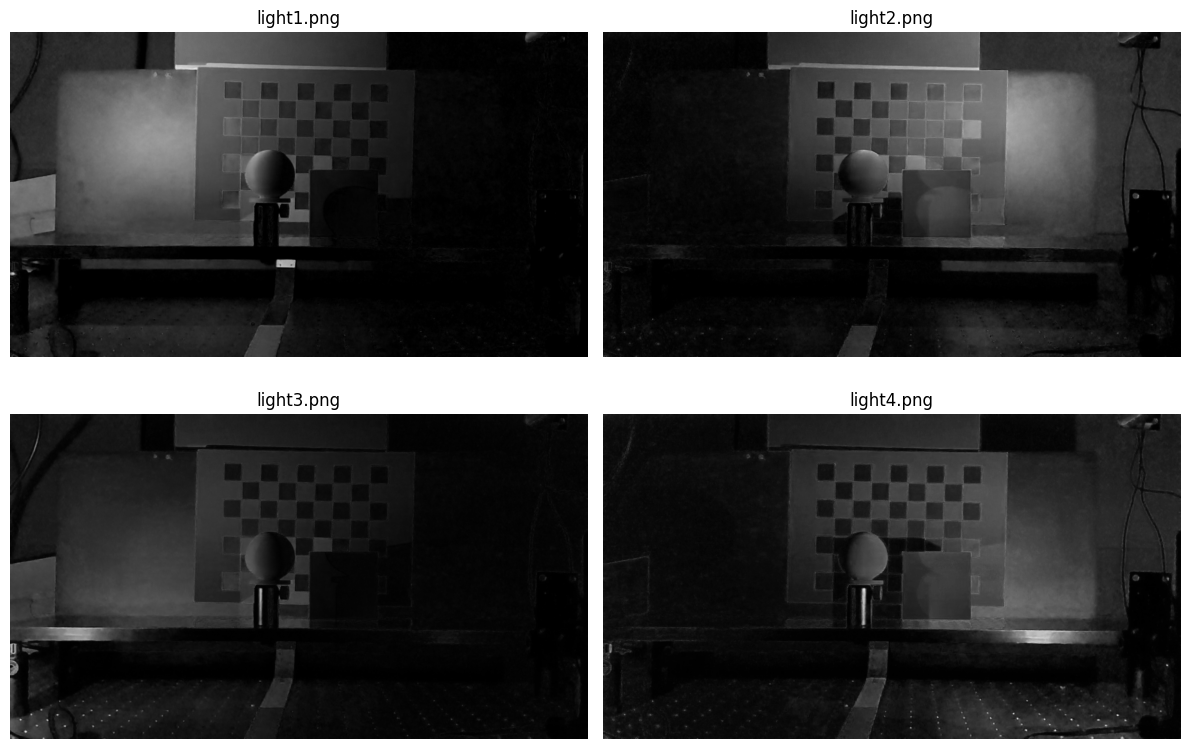

In [5]:
plt.figure(figsize=(12, 8))

for i, filename in enumerate(image_files):
    img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

    plt.subplot(2, 2, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(filename)
    plt.axis("off")

plt.tight_layout()
plt.show()

Photometric Stereo program

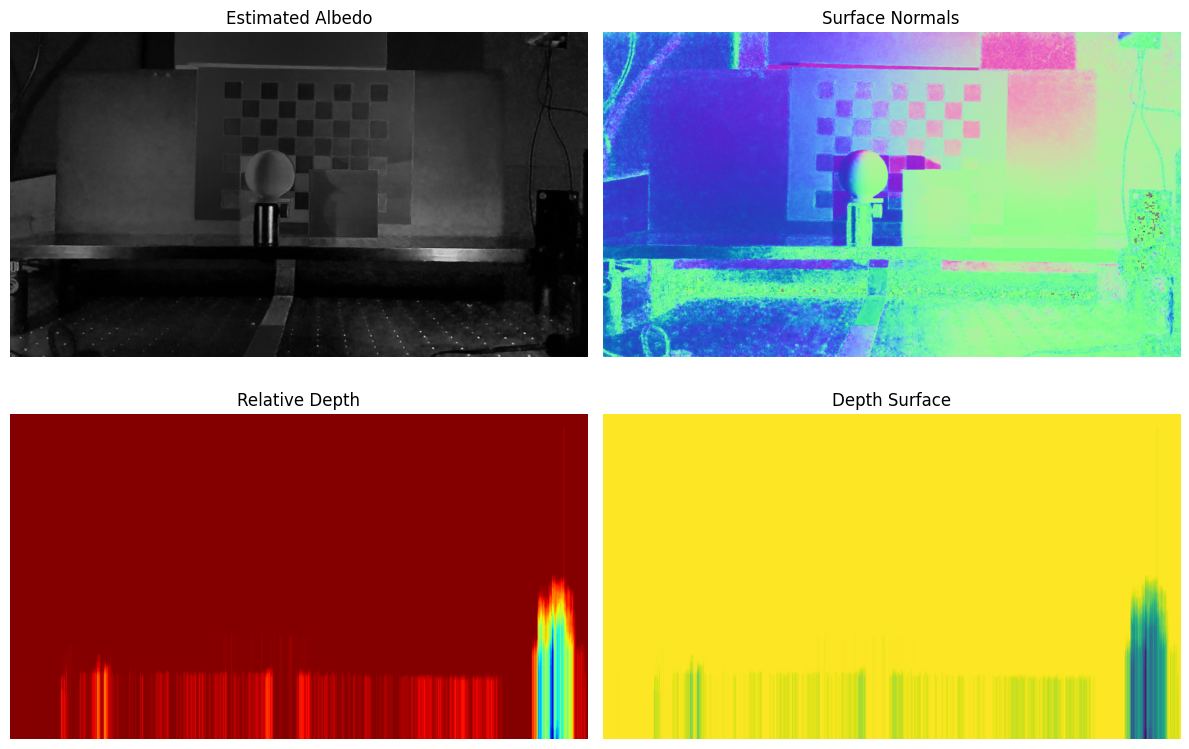

True

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read four grayscale images of the same object
files = ["light1.png", "light2.png", "light3.png", "light4.png"]

images = []

for f in files:
    img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)

    if img is None:
        raise FileNotFoundError(f"Could not read {f}")

    images.append(img.astype(np.float64) / 255.0)

# 2. Stack the images: shape = (number_of_images, height, width)
I = np.stack(images, axis=0)

# 3. Known light directions [lx, ly, lz]
# These are the example directions from the practical document.
L = np.array([
    [ 0.0, 0.0, 1.0],
    [ 0.6, 0.0, 0.8],
    [-0.6, 0.0, 0.8],
    [ 0.0, 0.6, 0.8]
], dtype=np.float64)

# 4. Normalize every light direction
L = L / np.linalg.norm(L, axis=1, keepdims=True)

# 5. Compute the pseudo-inverse of the lighting matrix
L_pinv = np.linalg.pinv(L)

# 6. Rearrange image data so each pixel has an intensity vector
m, h, w = I.shape
I_pixels = I.reshape(m, -1)

# 7. Estimate scaled surface normals g = L+ I
G = L_pinv @ I_pixels

# 8. Calculate albedo = magnitude of the scaled normal
albedo = np.linalg.norm(G, axis=0)

# 9. Normalize G to obtain unit surface normals
normals = G / (albedo[None, :] + 1e-8)

# 10. Extract normal components
nx = normals[0].reshape(h, w)
ny = normals[1].reshape(h, w)
nz = normals[2].reshape(h, w)

# 11. Convert normals to surface gradients
p = -nx / (nz + 1e-8)
q = -ny / (nz + 1e-8)

# 12. Simple path integration to obtain a relative depth map
depth = np.zeros((h, w), dtype=np.float64)

# Integrate p along x direction
for y in range(h):
    depth[y, 1:] = np.cumsum(p[y, :-1])

# Add q contribution along y direction
for x in range(w):
    depth[1:, x] += np.cumsum(q[:-1, x])

# 13. Normalize depth only for visualization
depth_vis = cv2.normalize(
    depth, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

# 14. Normalize albedo for visualization
albedo_vis = cv2.normalize(
    albedo.reshape(h, w), None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

# 15. Display results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(albedo_vis, cmap="gray")
plt.title("Estimated Albedo")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(np.dstack([
    (nx + 1) / 2,
    (ny + 1) / 2,
    (nz + 1) / 2
]))
plt.title("Surface Normals")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(depth_vis, cmap="jet")
plt.title("Relative Depth")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(depth, cmap="viridis")
plt.title("Depth Surface")
plt.axis("off")

plt.tight_layout()
plt.show()

# 16. Save outputs
cv2.imwrite("photometric_albedo.png", albedo_vis)
cv2.imwrite("photometric_depth.png", depth_vis)

In [8]:
from google.colab import files

files.download("photometric_albedo.png")
files.download("photometric_depth.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

DFD

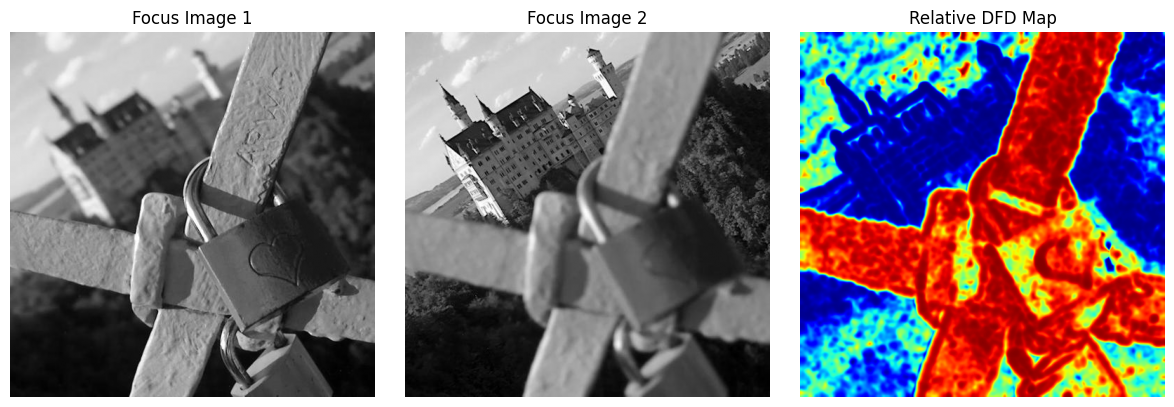

True

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read the two images captured at different focus settings
img1 = cv2.imread("focus_near.jpg", cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread("focus_far.jpg", cv2.IMREAD_GRAYSCALE)

# 2. Check that both images were loaded
if img1 is None or img2 is None:
    raise FileNotFoundError("Check the image names and file paths.")

# 3. Make both images the same size
img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))

# 4. Apply a small Gaussian blur to reduce sensor noise
img1_s = cv2.GaussianBlur(img1, (3, 3), 0)
img2_s = cv2.GaussianBlur(img2, (3, 3), 0)

# 5. Calculate the Laplacian response
lap1 = cv2.Laplacian(img1_s, cv2.CV_64F)
lap2 = cv2.Laplacian(img2_s, cv2.CV_64F)

# 6. Estimate local focus using squared Laplacian
kernel = (15, 15)
focus1 = cv2.GaussianBlur(lap1 ** 2, kernel, 0)
focus2 = cv2.GaussianBlur(lap2 ** 2, kernel, 0)

# 7. Compare the focus measures
eps = 1e-8
focus_diff = (focus1 - focus2) / (focus1 + focus2 + eps)

# 8. Convert the relative focus difference into a displayable map
depth_map = cv2.normalize(
    focus_diff, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

# 9. Display the input images and the DFD result
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img1, cmap="gray")
plt.title("Focus Image 1")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(img2, cmap="gray")
plt.title("Focus Image 2")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(depth_map, cmap="jet")
plt.title("Relative DFD Map")
plt.axis("off")

plt.tight_layout()
plt.show()

# 10. Save the result
cv2.imwrite("dfd_relative_depth.png", depth_map)

In [10]:
from google.colab import files

files.download("dfd_relative_depth.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

DFD observation

The Depth from Defocus method compares two images captured at different focus settings. The Laplacian operator measures changes in image intensity, and its squared response is used to estimate local sharpness. Comparing the focus measures highlights regions that are sharper in one image than in the other. The resulting map provides a relative focus/depth visualization. The method does not directly provide physical depth measurements, and image misalignment can affect the result.

Photometric Stereo observation

The Photometric Stereo method uses multiple images of the same object captured under different lighting directions. Changes in intensity are used to estimate the surface normals at each pixel. These normals are converted into surface gradients and integrated to obtain a relative depth map. The albedo and normal maps provide additional information about the surface. The quality of the reconstruction depends on the lighting directions, image quality, and assumptions made by the algorithm.

Adjust these observations according to what you actually see in the output.

TASK 1 — Change the DFD Window Size
Objective

Change the local focus window from (15, 15) to (7, 7) and (31, 31), then compare the three DFD maps.

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img1 = cv2.imread("focus_near.jpg", cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread("focus_far.jpg", cv2.IMREAD_GRAYSCALE)

if img1 is None or img2 is None:
    raise FileNotFoundError("Check focus_near.jpg and focus_far.jpg")

img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))

img1_s = cv2.GaussianBlur(img1, (3, 3), 0)
img2_s = cv2.GaussianBlur(img2, (3, 3), 0)

lap1 = cv2.Laplacian(img1_s, cv2.CV_64F)
lap2 = cv2.Laplacian(img2_s, cv2.CV_64F)

print("DFD images loaded successfully.")

DFD images loaded successfully.


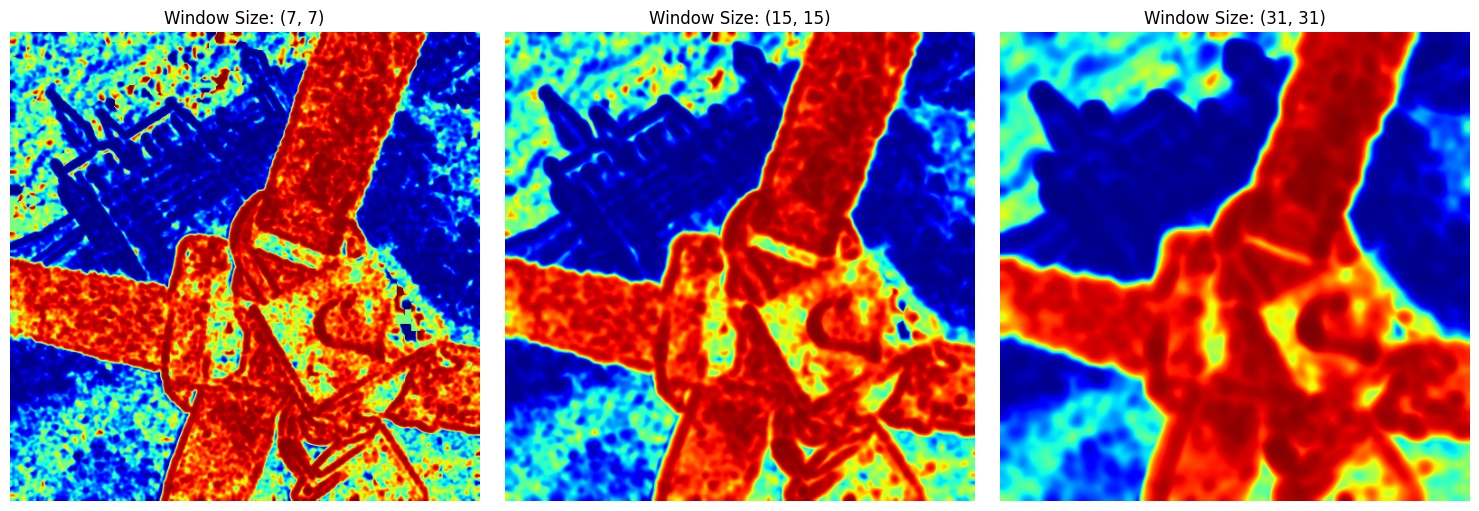

True

In [12]:
# TASK 1: Compare different DFD window sizes

window_sizes = [(7, 7), (15, 15), (31, 31)]
dfd_results = {}

eps = 1e-8

for kernel in window_sizes:

    focus1 = cv2.GaussianBlur(lap1 ** 2, kernel, 0)
    focus2 = cv2.GaussianBlur(lap2 ** 2, kernel, 0)

    focus_diff = (focus1 - focus2) / (
        focus1 + focus2 + eps
    )

    depth_map = cv2.normalize(
        focus_diff, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)

    dfd_results[kernel] = depth_map

# Display the three results
plt.figure(figsize=(15, 5))

for i, kernel in enumerate(window_sizes):

    plt.subplot(1, 3, i + 1)
    plt.imshow(dfd_results[kernel], cmap="jet")
    plt.title(f"Window Size: {kernel}")
    plt.axis("off")

plt.tight_layout()
plt.show()

# Save the three results
cv2.imwrite("dfd_window_7.png", dfd_results[(7, 7)])
cv2.imwrite("dfd_window_15.png", dfd_results[(15, 15)])
cv2.imwrite("dfd_window_31.png", dfd_results[(31, 31)])

The DFD algorithm was tested using three different window sizes: 7 × 7, 15 × 15, and 31 × 31. The 7 × 7 window preserves fine details but produces a noisier depth map. The 15 × 15 window provides a balance between detail and smoothness. The 31 × 31 window produces a smoother map by averaging focus information over a larger area, but some fine details and boundaries become less distinct. Therefore, the window size affects the trade-off between noise reduction and the localization of depth information.


TASK 2 — Compare Focus Measures
Objective

Compare the squared-Laplacian approach in the original program with a second focus measure based on the local variance of the Laplacian.

In [13]:
focus1 = cv2.GaussianBlur(lap1 ** 2, (15, 15), 0)
focus2 = cv2.GaussianBlur(lap2 ** 2, (15, 15), 0)

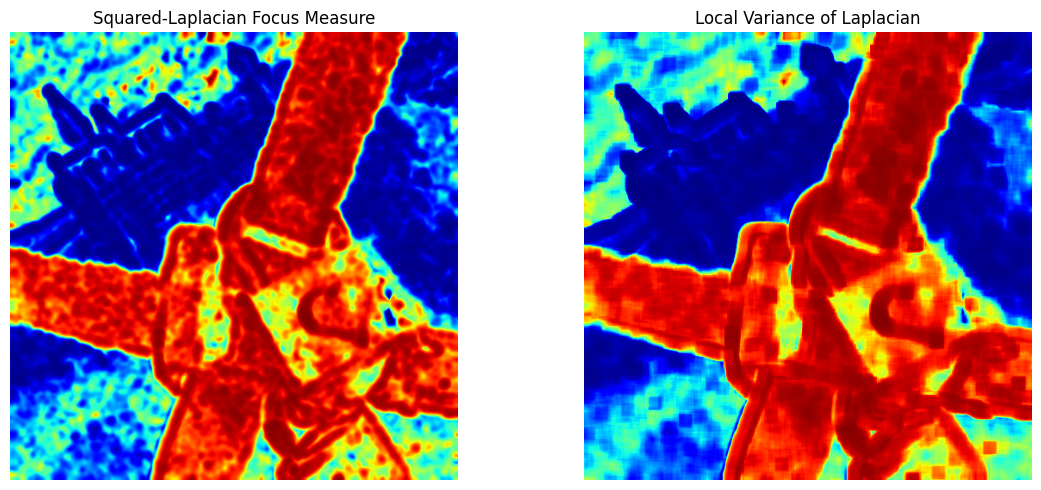

True

In [14]:
# TASK 2: Compare two focus measures

kernel = (15, 15)
eps = 1e-8

# Method 1: Squared-Laplacian approach from the practical
focus1_squared = cv2.GaussianBlur(lap1 ** 2, kernel, 0)
focus2_squared = cv2.GaussianBlur(lap2 ** 2, kernel, 0)

diff_squared = (
    (focus1_squared - focus2_squared) /
    (focus1_squared + focus2_squared + eps)
)

map_squared = cv2.normalize(
    diff_squared, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)


# Method 2: Local variance of the Laplacian
def local_laplacian_variance(lap, kernel_size=15):

    mean = cv2.blur(
        lap, (kernel_size, kernel_size)
    )

    mean_square = cv2.blur(
        lap ** 2, (kernel_size, kernel_size)
    )

    variance = mean_square - mean ** 2

    return np.maximum(variance, 0)


focus1_variance = local_laplacian_variance(lap1, 15)
focus2_variance = local_laplacian_variance(lap2, 15)

diff_variance = (
    (focus1_variance - focus2_variance) /
    (focus1_variance + focus2_variance + eps)
)

map_variance = cv2.normalize(
    diff_variance, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)


# Display the comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(map_squared, cmap="jet")
plt.title("Squared-Laplacian Focus Measure")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(map_variance, cmap="jet")
plt.title("Local Variance of Laplacian")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save the outputs
cv2.imwrite("dfd_squared_laplacian.png", map_squared)
cv2.imwrite("dfd_laplacian_variance.png", map_variance)

Two focus measures were compared: the squared-Laplacian approach and the local variance of the Laplacian. Both methods use changes in image intensity to estimate sharpness. The local variance measures how much the Laplacian responses vary within a window, while the original approach averages the squared responses. Their output maps may differ in their response to local image structures and noise. The comparison shows that the choice of focus measure influences the resulting DFD visualization.

TASK 3 — DFD Alignment Experiment
Objective

Shift one DFD image by a few pixels and observe how misalignment affects the result.

Your practical explains that the images should be aligned and that misalignment can create false depth.

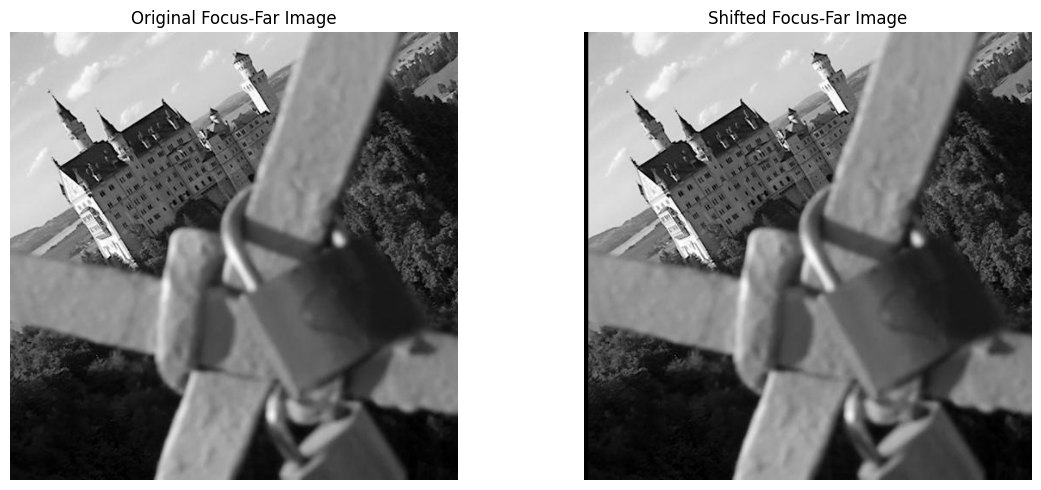

True

In [15]:
# TASK 3: Shift one DFD image by five pixels

rows, cols = img2.shape

M = np.float32([
    [1, 0, 5],
    [0, 1, 0]
])

img2_shifted = cv2.warpAffine(
    img2,
    M,
    (cols, rows)
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img2, cmap="gray")
plt.title("Original Focus-Far Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img2_shifted, cmap="gray")
plt.title("Shifted Focus-Far Image")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite("focus_far_shifted.jpg", img2_shifted)

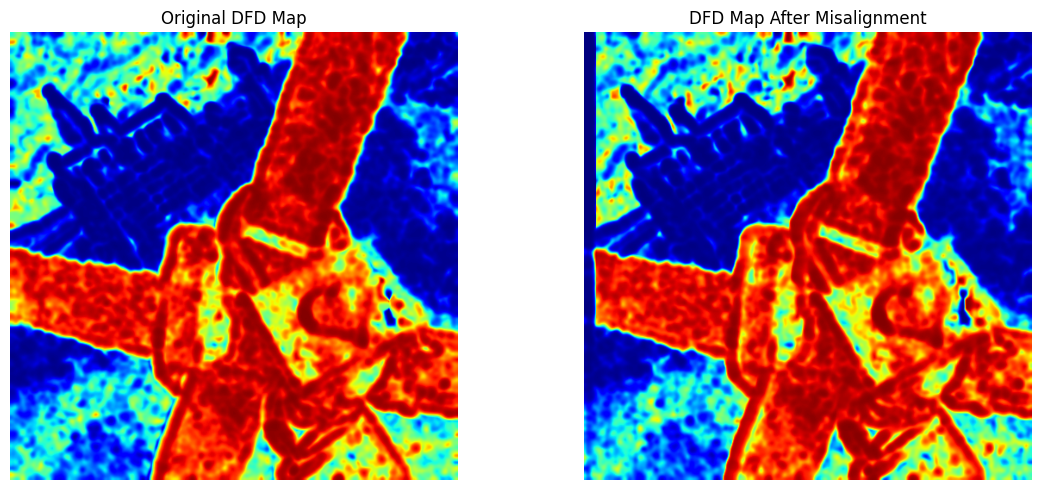

True

In [16]:
# Calculate focus measures for the shifted experiment

img2_shifted_s = cv2.GaussianBlur(
    img2_shifted, (3, 3), 0
)

lap2_shifted = cv2.Laplacian(
    img2_shifted_s, cv2.CV_64F
)

kernel = (15, 15)
eps = 1e-8

focus1 = cv2.GaussianBlur(lap1 ** 2, kernel, 0)
focus2_shifted = cv2.GaussianBlur(
    lap2_shifted ** 2, kernel, 0
)

focus_diff_shifted = (
    (focus1 - focus2_shifted) /
    (focus1 + focus2_shifted + eps)
)

depth_shifted = cv2.normalize(
    focus_diff_shifted,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(dfd_results[(15, 15)], cmap="jet")
plt.title("Original DFD Map")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(depth_shifted, cmap="jet")
plt.title("DFD Map After Misalignment")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite("dfd_alignment_experiment.png", depth_shifted)

The DFD algorithm was tested using the original focus images and an image shifted horizontally by five pixels. The shift changes the spatial correspondence between the two images. Consequently, differences in the focus measures may occur even where the changes are caused by misalignment rather than defocus. This can introduce false depth variations into the DFD map. The experiment demonstrates why image alignment is important for reliable DFD results

TASK 4 — Photometric Stereo with Different Light Directions
Objective

Change the lighting matrix L and observe how the estimated surface normals and depth map change.

In [17]:
L = np.array([
    [ 0.0, 0.0, 1.0],
    [ 0.6, 0.0, 0.8],
    [-0.6, 0.0, 0.8],
    [ 0.0, 0.6, 0.8]
], dtype=np.float64)

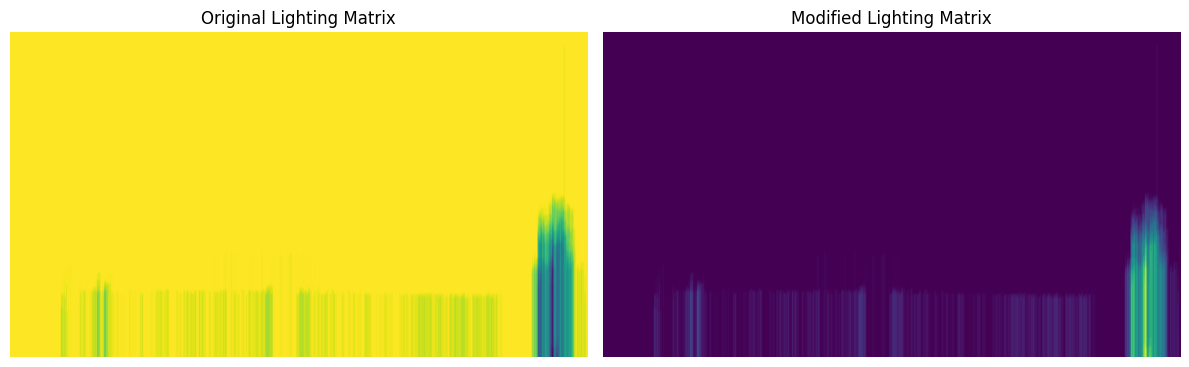

True

In [18]:
# TASK 4: Change the assumed light directions

# Save the original results for comparison
normals_original = normals.copy()
depth_original = depth.copy()

# Modified example lighting directions
L_modified = np.array([
    [ 0.3,  0.0, 0.954],
    [ 0.8,  0.0, 0.6],
    [-0.8,  0.0, 0.6],
    [ 0.0, -0.6, 0.8]
], dtype=np.float64)

# Normalize the modified directions
L_modified = L_modified / np.linalg.norm(
    L_modified, axis=1, keepdims=True
)

# Estimate surface normals using the modified matrix
L_pinv_modified = np.linalg.pinv(L_modified)

G_modified = L_pinv_modified @ I_pixels

albedo_modified = np.linalg.norm(
    G_modified, axis=0
)

normals_modified = G_modified / (
    albedo_modified[None, :] + 1e-8
)

nx_modified = normals_modified[0].reshape(h, w)
ny_modified = normals_modified[1].reshape(h, w)
nz_modified = normals_modified[2].reshape(h, w)

# Calculate gradients
p_modified = -nx_modified / (nz_modified + 1e-8)
q_modified = -ny_modified / (nz_modified + 1e-8)

# Integrate gradients
depth_modified = np.zeros((h, w), dtype=np.float64)

for y in range(h):
    depth_modified[y, 1:] = np.cumsum(
        p_modified[y, :-1]
    )

for x in range(w):
    depth_modified[1:, x] += np.cumsum(
        q_modified[:-1, x]
    )

# Normalize for visualization
depth_modified_vis = cv2.normalize(
    depth_modified, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

# Display comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(depth_original, cmap="viridis")
plt.title("Original Lighting Matrix")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(depth_modified, cmap="viridis")
plt.title("Modified Lighting Matrix")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(
    "photometric_depth_modified_lighting.png",
    depth_modified_vis
)

The Photometric Stereo program was tested using two different lighting matrices. The lighting matrix is used to estimate the surface normals from the measured image intensities. Changing the assumed light directions changes the estimated normals and the gradients derived from them. These changes can affect the reconstructed relative depth map. The experiment demonstrates that accurate knowledge of the lighting directions is important for reliable Photometric Stereo reconstruction.

TASK 5 — Reduce the Number of Images
Objective

Modify the Photometric Stereo program to use three images instead of four and compare the results.

The original program uses four images and four corresponding lighting directions. When reducing the number of images, the lighting matrix must also be reduced to three rows.

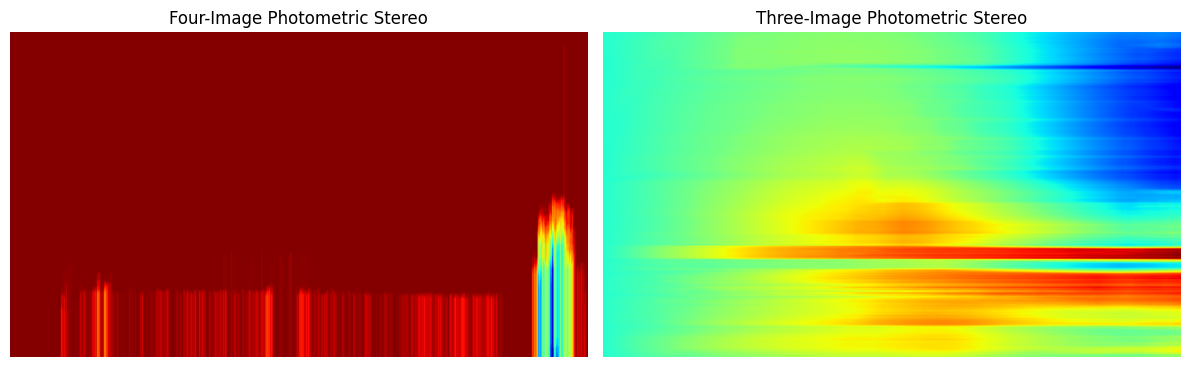

True

In [19]:
# TASK 5: Photometric Stereo using three images

# Select three images
I_three = I[:3, :, :]

# Select the corresponding three light directions
L_three = L[:3, :]

# Compute the pseudo-inverse
L_three_pinv = np.linalg.pinv(L_three)

# Rearrange image data
m3, h, w = I_three.shape
I_pixels_three = I_three.reshape(m3, -1)

# Estimate scaled surface normals
G_three = L_three_pinv @ I_pixels_three

# Calculate albedo
albedo_three = np.linalg.norm(
    G_three, axis=0
)

# Normalize surface normals
normals_three = G_three / (
    albedo_three[None, :] + 1e-8
)

# Extract normal components
nx_three = normals_three[0].reshape(h, w)
ny_three = normals_three[1].reshape(h, w)
nz_three = normals_three[2].reshape(h, w)

# Convert normals to gradients
p_three = -nx_three / (nz_three + 1e-8)
q_three = -ny_three / (nz_three + 1e-8)

# Integrate gradients
depth_three = np.zeros((h, w), dtype=np.float64)

for y in range(h):
    depth_three[y, 1:] = np.cumsum(
        p_three[y, :-1]
    )

for x in range(w):
    depth_three[1:, x] += np.cumsum(
        q_three[:-1, x]
    )

# Normalize for visualization
depth_three_vis = cv2.normalize(
    depth_three, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

# Display the comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(depth_vis, cmap="jet")
plt.title("Four-Image Photometric Stereo")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(depth_three_vis, cmap="jet")
plt.title("Three-Image Photometric Stereo")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(
    "photometric_depth_three_images.png",
    depth_three_vis
)

The Photometric Stereo algorithm was modified to use three images instead of four. The lighting matrix was reduced to three corresponding light directions. The estimated normals and depth map were then compared with the original four-image result. Using three images reduces the number of measurements available for estimating surface orientation, while four images provide an additional measurement that can improve robustness. The accuracy of both results depends on the lighting directions and the quality of the input images.

TASK 6 — Mask the Background
Objective

Create a binary object mask and calculate the depth and normals only inside the object.

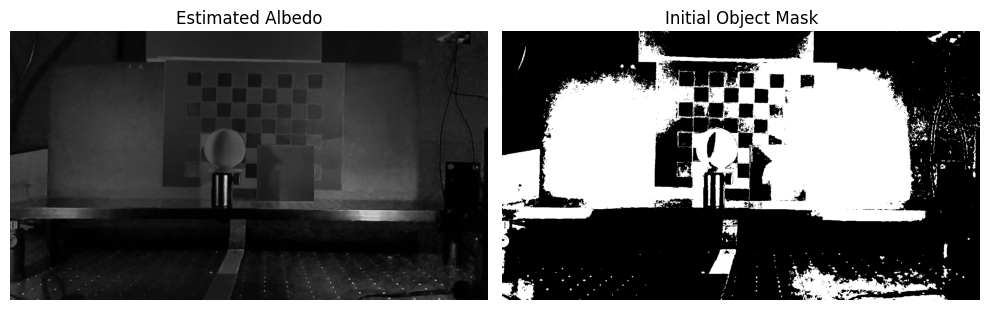

True

In [20]:
# TASK 6: Create an initial background mask

albedo_image = albedo.reshape(h, w)

# Normalize albedo for thresholding
albedo_normalized = cv2.normalize(
    albedo_image,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

# Create a binary mask using Otsu thresholding
_, object_mask = cv2.threshold(
    albedo_normalized,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(albedo_normalized, cmap="gray")
plt.title("Estimated Albedo")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(object_mask, cmap="gray")
plt.title("Initial Object Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite("photometric_object_mask.png", object_mask)

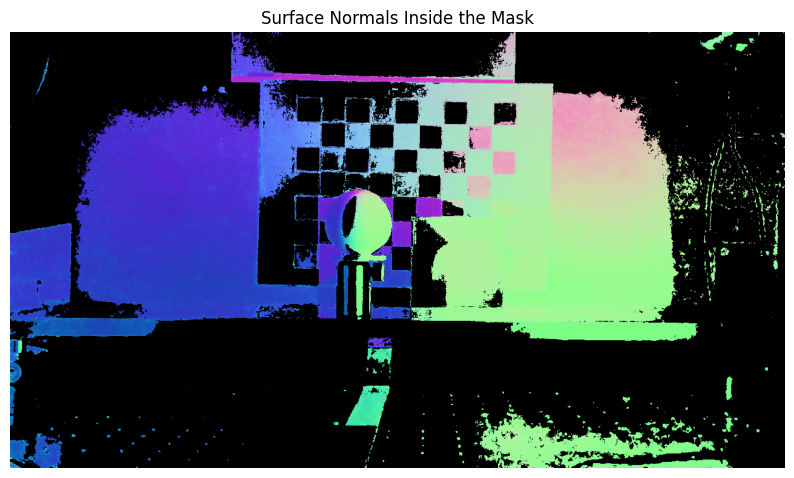

In [21]:
# Convert mask to Boolean
mask = object_mask > 0

# Apply mask to the normal components
nx_masked = np.where(mask, nx, np.nan)
ny_masked = np.where(mask, ny, np.nan)
nz_masked = np.where(mask, nz, np.nan)

# Display masked surface normals
plt.figure(figsize=(10, 6))

plt.imshow(
    np.dstack([
        np.nan_to_num((nx_masked + 1) / 2),
        np.nan_to_num((ny_masked + 1) / 2),
        np.nan_to_num((nz_masked + 1) / 2)
    ])
)

plt.title("Surface Normals Inside the Mask")
plt.axis("off")
plt.show()

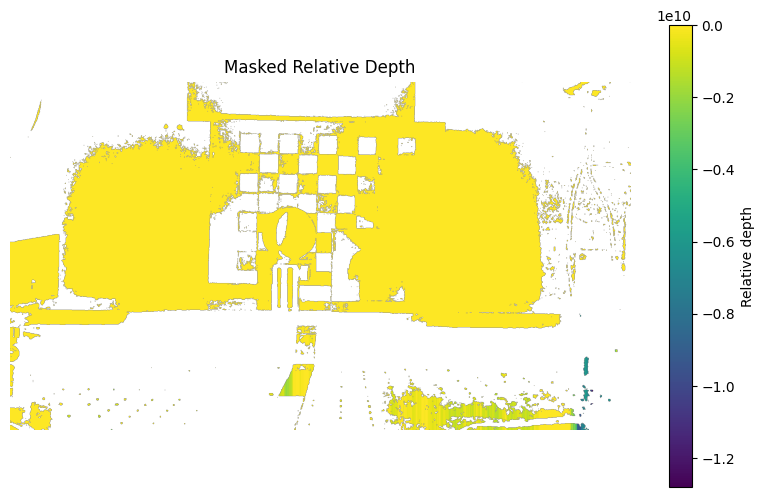

In [22]:
# Apply the same mask to the relative depth
depth_masked = np.where(mask, depth, np.nan)

plt.figure(figsize=(10, 6))

plt.imshow(depth_masked, cmap="viridis")
plt.colorbar(label="Relative depth")
plt.title("Masked Relative Depth")
plt.axis("off")

plt.show()

A binary mask was created to separate selected object pixels from the background. The mask was applied to the estimated surface normals and relative depth map. Excluding background pixels helps focus the visualization on the selected region and prevents those pixels from being interpreted as part of the object. The quality of this result depends on the accuracy of the mask. If the mask includes background regions or excludes parts of the object, the visualization will remain incomplete or inaccurate.

TASK 7 — Final Comparison of DFD and Photometric Stereo

Compare both methods using the same object or scene, considering their input requirements, depth cues, strengths, weaknesses, and outputs.

| Aspect                   | Depth from Defocus (DFD)                               | Photometric Stereo                                                             |
| ------------------------ | ------------------------------------------------------ | ------------------------------------------------------------------------------ |
| Input images             | Two images captured at different focus settings        | Three or more images captured under different lighting directions              |
| Main principle           | Uses differences in image sharpness                    | Uses intensity changes caused by illumination                                  |
| Camera position          | Should remain fixed                                    | Should remain fixed                                                            |
| Main intermediate result | Local focus measures                                   | Surface normals                                                                |
| Final result             | Relative focus/depth map                               | Surface normals and relative depth map                                         |
| Main advantage           | Demonstrates depth cues using focus differences        | Provides information about surface orientation                                 |
| Main limitation          | Requires suitable focus differences and aligned images | Requires appropriate lighting directions and suitable surface reflectance      |
| Physical depth           | Requires calibration for metric depth                  | The simple implementation produces relative depth, not calibrated metric depth |


DFD and Photometric Stereo are two methods for recovering shape information from images. DFD uses differences in focus and blur to estimate relative depth, whereas Photometric Stereo uses changes in illumination to estimate surface normals and reconstruct relative depth. DFD requires images captured at different focus settings, while Photometric Stereo requires images captured under different lighting directions. Both methods depend on the quality of the input images and their assumptions. The experiments demonstrate how different visual cues can be used to infer three-dimensional information from two-dimensional images.